In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

# Project paths
PROJECT_DIR = Path.home() / "Climate-Change-Awareness-Dashboard"
PRECIPITATION_DIR = PROJECT_DIR / "precipitation"

# Select one year of precipitation data
rainfall_path = PRECIPITATION_DIR / "data" / "interim" / "imd_rainfall_1951.csv"

# Temperature dataset
temperature_path = (
    PROJECT_DIR / "data" / "processed_india" / "india_monthly_temperature.csv"
)

# Load datasets
rainfall_df = pd.read_csv(rainfall_path)
temperature_df = pd.read_csv(temperature_path)

In [4]:
print("Rainfall dataset:")
print("Shape:", rainfall_df.shape)
print("Columns:", rainfall_df.columns.tolist())
display(rainfall_df.head())

print("\nTemperature dataset:")
print("Shape:", temperature_df.shape)
print("Columns:", temperature_df.columns.tolist())
display(temperature_df.head())

Rainfall dataset:
Shape: (1811860, 4)
Columns: ['date', 'latitude', 'longitude', 'rainfall_mm']


,date,latitude,longitude,rainfall_mm
0,1951-01-01,8.25,77.00,0.000000
1,1951-01-01,8.25,77.25,0.000000
2,1951-01-01,8.25,77.50,5.228102
3,1951-01-01,8.25,77.75,2.281836
4,1951-01-01,8.50,76.75,0.000000



Temperature dataset:
Shape: (322200, 17)
Columns: ['date', 'year', 'month', 'cell_id', 'lat', 'lon', 'tmax_mean', 'tmin_mean', 'tmean_mean', 'tmax_days', 'tmin_days', 'tmax_normal', 'tmin_normal', 'tmean_normal', 'tmax_anom', 'tmin_anom', 'tmean_anom']


,date,year,month,cell_id,lat,lon,tmax_mean,tmin_mean,tmean_mean,tmax_days,tmin_days,tmax_normal,tmin_normal,tmean_normal,tmax_anom,tmin_anom,tmean_anom
0,1951-01-01,1951,1,8.5_73.5,8.5,73.5,31.165,22.778,26.972,31,31,31.784,22.209,26.996,-0.619,0.569,-0.025
1,1951-01-01,1951,1,8.5_76.5,8.5,76.5,29.918,21.406,25.662,31,31,30.252,20.761,25.506,-0.334,0.645,0.156
2,1951-01-01,1951,1,8.5_77.5,8.5,77.5,31.051,22.405,26.728,31,31,31.325,21.676,26.501,-0.275,0.728,0.227
3,1951-01-01,1951,1,8.5_78.5,8.5,78.5,29.852,22.401,26.126,31,31,30.257,21.747,26.002,-0.404,0.654,0.125
4,1951-01-01,1951,1,9.5_76.5,9.5,76.5,30.079,20.919,25.499,31,31,30.535,20.346,25.441,-0.456,0.573,0.059


In [5]:
# Extract unique coordinates
rain_lat = np.sort(rainfall_df["latitude"].unique())
rain_lon = np.sort(rainfall_df["longitude"].unique())

temp_lat = np.sort(temperature_df["lat"].unique())
temp_lon = np.sort(temperature_df["lon"].unique())

# Calculate coordinate spacing
def inspect_grid(name, latitudes, longitudes):
    print(f"\n{name}")
    print("-" * 40)

    print("Unique latitudes:", len(latitudes))
    print("Unique longitudes:", len(longitudes))

    print("Latitude range:", latitudes.min(), "to", latitudes.max())
    print("Longitude range:", longitudes.min(), "to", longitudes.max())

    print("Latitude spacing:", np.unique(np.round(np.diff(latitudes), 6)))
    print("Longitude spacing:", np.unique(np.round(np.diff(longitudes), 6)))


inspect_grid("RAINFALL GRID", rain_lat, rain_lon)
inspect_grid("TEMPERATURE GRID", temp_lat, temp_lon)


RAINFALL GRID
----------------------------------------
Unique latitudes: 117
Unique longitudes: 118
Latitude range: 8.25 to 37.25
Longitude range: 68.0 to 97.25
Latitude spacing: [0.25]
Longitude spacing: [0.25]

TEMPERATURE GRID
----------------------------------------
Unique latitudes: 29
Unique longitudes: 30
Latitude range: 8.5 to 36.5
Longitude range: 68.5 to 97.5
Latitude spacing: [1.]
Longitude spacing: [1.]


In [6]:
rain_cells = set(
    zip(
        rainfall_df["latitude"].round(6),
        rainfall_df["longitude"].round(6)
    )
)

temp_cells = set(
    zip(
        temperature_df["lat"].round(6),
        temperature_df["lon"].round(6)
    )
)

common_cells = rain_cells.intersection(temp_cells)

print("Rainfall grid cells:", len(rain_cells))
print("Temperature grid cells:", len(temp_cells))
print("Exactly matching cells:", len(common_cells))
print("Rainfall-only cells:", len(rain_cells - temp_cells))
print("Temperature-only cells:", len(temp_cells - rain_cells))

Rainfall grid cells: 4964
Temperature grid cells: 358
Exactly matching cells: 308
Rainfall-only cells: 4656
Temperature-only cells: 50


In [7]:
import imdlib as imd

TEMP_RAW_DIR = PROJECT_DIR / "data" / "raw" / "imd"

tmax_data = imd.open_data(
    "tmax",
    1951,
    1951,
    "yearwise",
    str(TEMP_RAW_DIR)
)

temperature_grid = tmax_data.get_xarray()

print(temperature_grid)

<xarray.Dataset> Size: 3MB
Dimensions:  (time: 365, lat: 31, lon: 31)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1951-01-01 1951-01-02 ... 1951-12-31
  * lat      (lat) float64 248B 7.5 8.5 9.5 10.5 11.5 ... 34.5 35.5 36.5 37.5
  * lon      (lon) float64 248B 67.5 68.5 69.5 70.5 71.5 ... 94.5 95.5 96.5 97.5
Data variables:
    tmax     (time, lat, lon) float64 3MB nan nan nan nan ... nan nan nan nan
Attributes:
    Conventions:  CF-1.7
    title:        IMD gridded data
    source:       https://imdpune.gov.in/
    history:      2026-11-09 08:35:21.921819 Python
    references:   
    comment:      
    crs:          epsg:4326


In [8]:
# Extract unique coordinates from the final temperature dataset
temp_lat_final = np.sort(temperature_df["lat"].unique())
temp_lon_final = np.sort(temperature_df["lon"].unique())

# Inspect coordinate values and spacing
print("TEMPERATURE CSV — FINAL GRID")
print("-" * 45)

print("First 15 latitudes:", temp_lat_final[:15])
print("First 15 longitudes:", temp_lon_final[:15])

print("\nLatitude range:", temp_lat_final.min(), "to", temp_lat_final.max())
print("Longitude range:", temp_lon_final.min(), "to", temp_lon_final.max())

print("\nLatitude spacing:", np.unique(np.round(np.diff(temp_lat_final), 6)))
print("Longitude spacing:", np.unique(np.round(np.diff(temp_lon_final), 6)))

print("\nUnique coordinate pairs:",
      temperature_df[["lat", "lon"]].drop_duplicates().shape[0])

TEMPERATURE CSV — FINAL GRID
---------------------------------------------
First 15 latitudes: [ 8.5  9.5 10.5 11.5 12.5 13.5 14.5 15.5 16.5 17.5 18.5 19.5 20.5 21.5
 22.5]
First 15 longitudes: [68.5 69.5 70.5 71.5 72.5 73.5 74.5 75.5 76.5 77.5 78.5 79.5 80.5 81.5
 82.5]

Latitude range: 8.5 to 36.5
Longitude range: 68.5 to 97.5

Latitude spacing: [1.]
Longitude spacing: [1.]

Unique coordinate pairs: 358


In [10]:
# Get unique rainfall grid cells
rain_cells = rainfall_df[
    ["latitude", "longitude"]
].drop_duplicates().copy()

# Get the actual temperature grid-cell centres
temp_cells = temperature_df[
    ["lat", "lon"]
].drop_duplicates().copy()

# Define the geographical boundaries of each temperature cell
temp_cells["lat_min"] = temp_cells["lat"] - 0.5
temp_cells["lat_max"] = temp_cells["lat"] + 0.5
temp_cells["lon_min"] = temp_cells["lon"] - 0.5
temp_cells["lon_max"] = temp_cells["lon"] + 0.5

# Assign rainfall cells based on geographical containment
rain_cells["temp_lat"] = np.nan
rain_cells["temp_lon"] = np.nan

for _, cell in temp_cells.iterrows():
    mask = (
        (rain_cells["latitude"] >= cell["lat_min"]) &
        (rain_cells["latitude"] < cell["lat_max"]) &
        (rain_cells["longitude"] >= cell["lon_min"]) &
        (rain_cells["longitude"] < cell["lon_max"])
    )

    rain_cells.loc[mask, "temp_lat"] = cell["lat"]
    rain_cells.loc[mask, "temp_lon"] = cell["lon"]

# Keep rainfall cells assigned to temperature locations
mapped_cells = rain_cells.dropna(
    subset=["temp_lat", "temp_lon"]
).copy()

# Count fine rainfall cells assigned to each temperature cell
cell_counts = (
    mapped_cells.groupby(["temp_lat", "temp_lon"])
    .size()
    .reset_index(name="rainfall_cell_count")
)

print("Rainfall grid cells:", len(rain_cells))
print("Mapped rainfall grid cells:", len(mapped_cells))
print("Unmapped rainfall grid cells:", len(rain_cells) - len(mapped_cells))

print("\nRainfall cells per temperature grid cell:")
display(cell_counts["rainfall_cell_count"].value_counts().sort_index())

display(cell_counts.head(10))

Rainfall grid cells: 4964
Mapped rainfall grid cells: 4891
Unmapped rainfall grid cells: 73

Rainfall cells per temperature grid cell:


rainfall_cell_count
1       4
2       4
3       8
4       7
5       5
6       9
7       9
8       5
9       3
10      7
11      8
12      7
13      8
14      2
15     12
16    254
Name: count, dtype: int64

,temp_lat,temp_lon,rainfall_cell_count
0,8.5,76.5,3
1,8.5,77.5,12
2,8.5,78.5,2
3,9.5,76.5,11
4,9.5,77.5,16
5,9.5,78.5,13
6,9.5,79.5,3
7,10.5,75.5,1
8,10.5,76.5,16
9,10.5,77.5,16


/home/sharanya/Climate-Change-Awareness-Dashboard/venv/lib/python3.12/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/home/sharanya/Climate-Change-Awareness-Dashboard/venv/lib/python3.12/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/home/sharanya/Climate-Change-Awareness-Dashboard/venv/lib/python3.12/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/home/sharanya/Climate-Change-Awareness-Dashboard/venv/lib/python3.12/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m

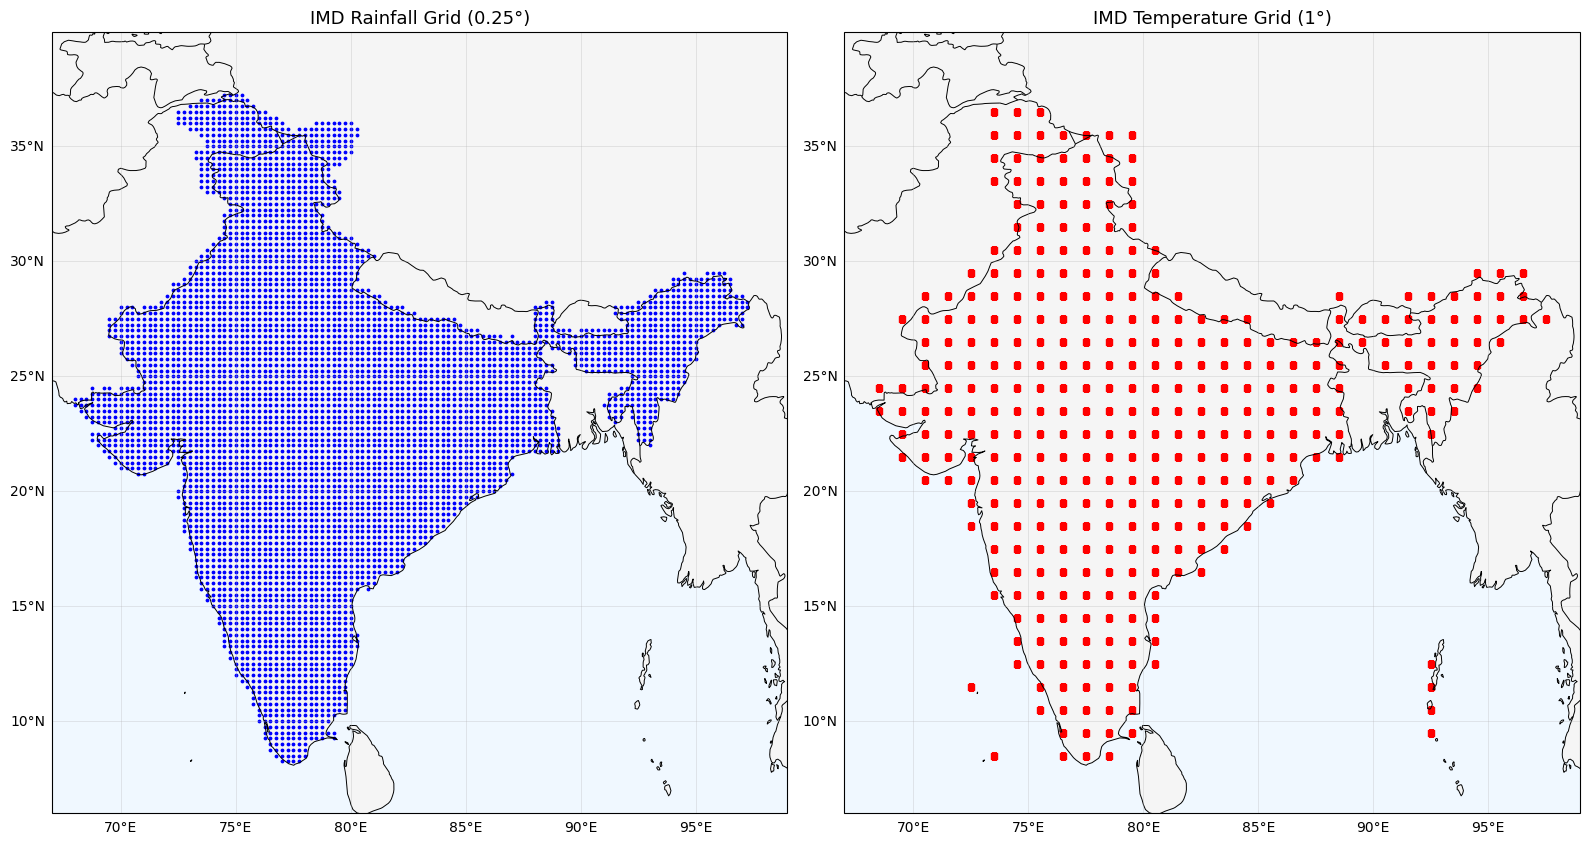

In [11]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Unique coordinate pairs
rain_cells = rainfall_df[
    ["latitude", "longitude"]
].drop_duplicates()

temp_cells = temperature_df[
    ["lat", "lon"]
].drop_duplicates()

# Create side-by-side maps
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 11),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

# Map 1: Rainfall grid
ax = axes[0]

ax.add_feature(cfeature.LAND, facecolor="whitesmoke")
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue")
ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linewidth=0.7)

ax.scatter(
    rain_cells["longitude"],
    rain_cells["latitude"],
    s=3,
    color="blue",
    transform=ccrs.PlateCarree()
)

ax.set_extent([67, 99, 6, 39])
ax.set_title("IMD Rainfall Grid (0.25°)", fontsize=13)

gl = ax.gridlines(draw_labels=True, linewidth=0.4, alpha=0.5)
gl.top_labels = False
gl.right_labels = False


# Map 2: Temperature grid
ax = axes[1]

ax.add_feature(cfeature.LAND, facecolor="whitesmoke")
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue")
ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linewidth=0.7)

ax.scatter(
    temp_cells["lon"],
    temp_cells["lat"],
    s=18,
    color="red",
    marker="s",
    transform=ccrs.PlateCarree()
)

ax.set_extent([67, 99, 6, 39])
ax.set_title("IMD Temperature Grid (1°)", fontsize=13)

gl = ax.gridlines(draw_labels=True, linewidth=0.4, alpha=0.5)
gl.top_labels = False
gl.right_labels = False

plt.tight_layout()
plt.show()

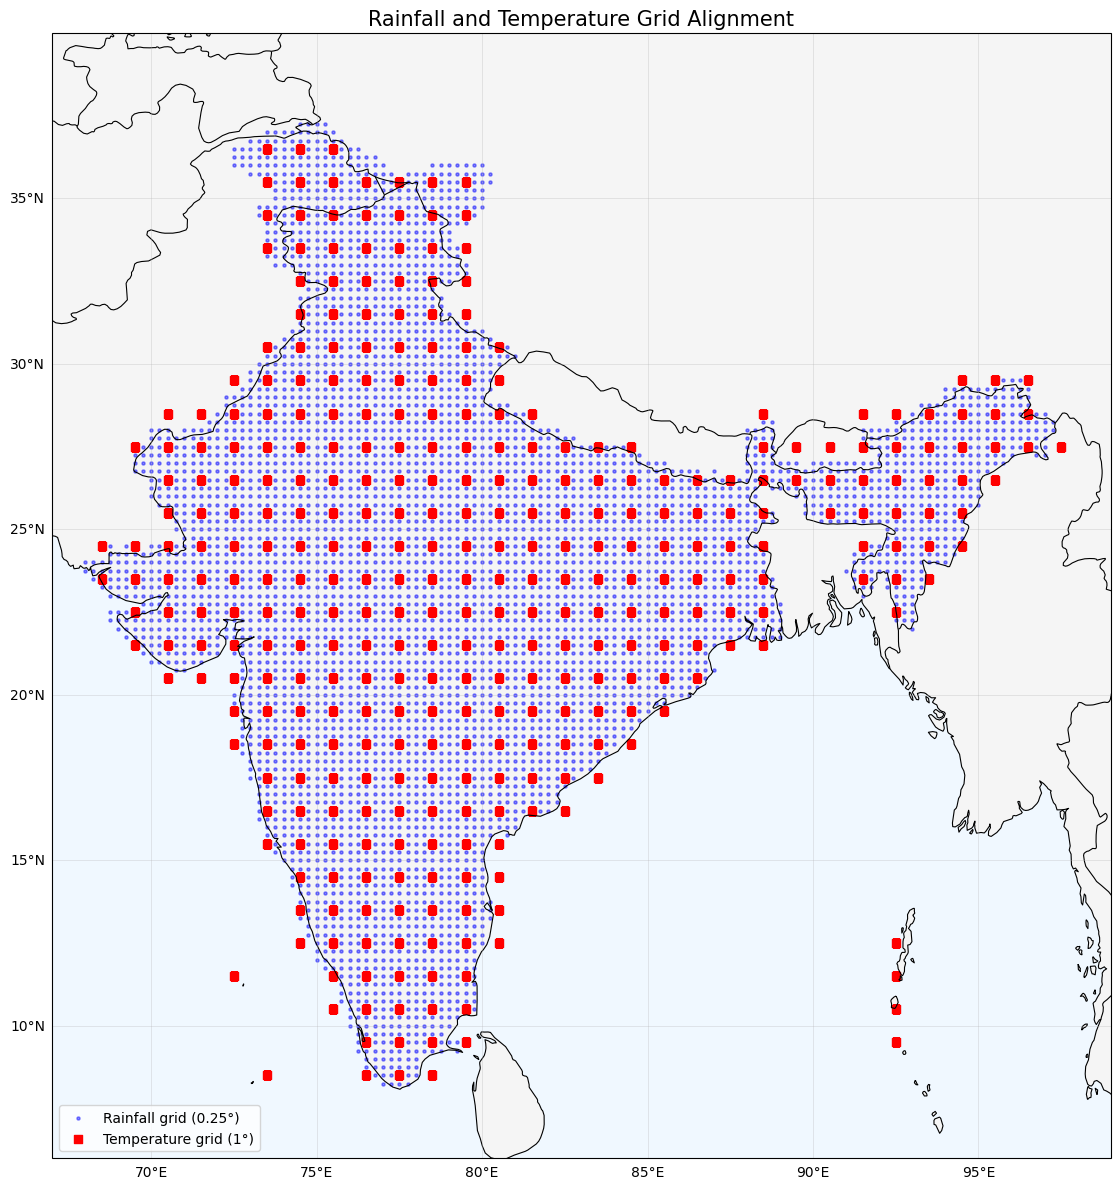

In [12]:
fig, ax = plt.subplots(
    figsize=(13, 12),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

ax.add_feature(cfeature.LAND, facecolor="whitesmoke")
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue")
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)

# Rainfall grid points
ax.scatter(
    rain_cells["longitude"],
    rain_cells["latitude"],
    s=5,
    color="blue",
    alpha=0.45,
    label="Rainfall grid (0.25°)",
    transform=ccrs.PlateCarree()
)

# Temperature grid points
ax.scatter(
    temp_cells["lon"],
    temp_cells["lat"],
    s=30,
    color="red",
    marker="s",
    label="Temperature grid (1°)",
    transform=ccrs.PlateCarree()
)

ax.set_extent([67, 99, 6, 39])

gl = ax.gridlines(draw_labels=True, linewidth=0.4, alpha=0.5)
gl.top_labels = False
gl.right_labels = False

ax.set_title("Rainfall and Temperature Grid Alignment", fontsize=15)
ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

/home/sharanya/Climate-Change-Awareness-Dashboard/venv/lib/python3.12/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/home/sharanya/Climate-Change-Awareness-Dashboard/venv/lib/python3.12/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/home/sharanya/Climate-Change-Awareness-Dashboard/venv/lib/python3.12/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


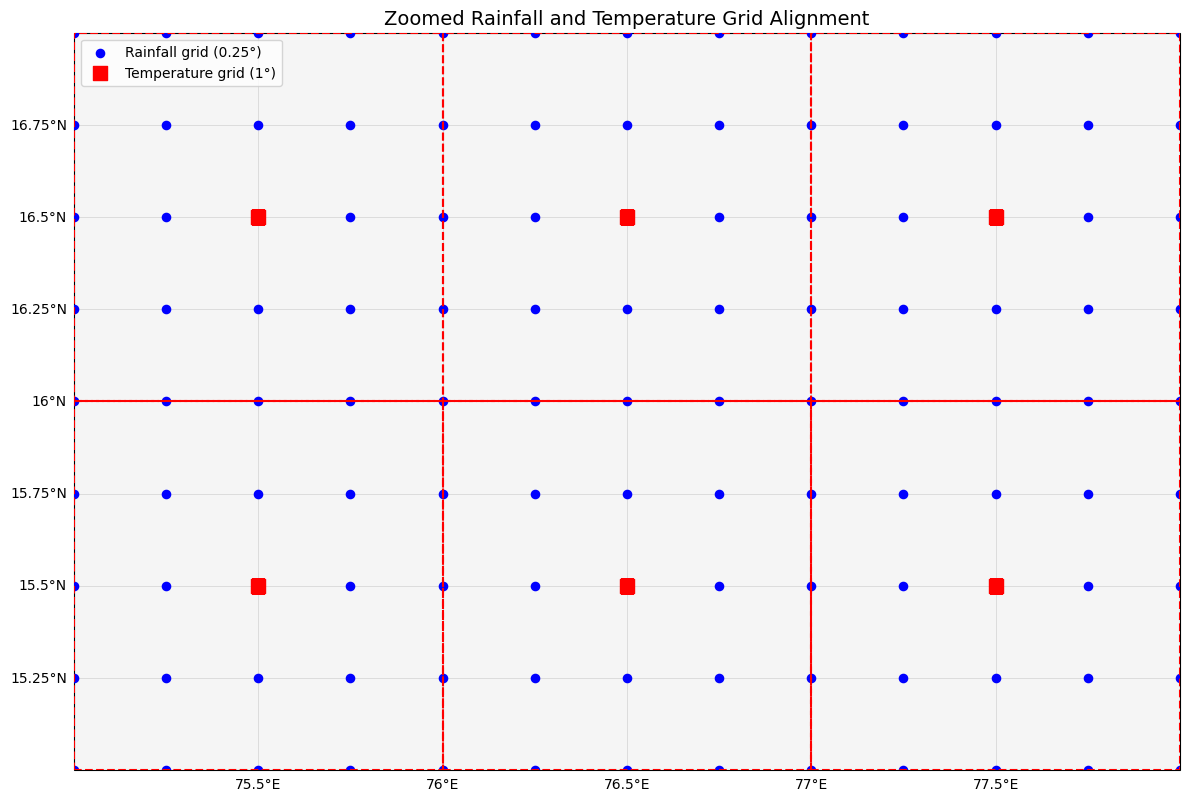

In [13]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle

# Select a small geographical region
lat_min, lat_max = 15, 17
lon_min, lon_max = 75, 78

# Filter rainfall points
rain_zoom = rain_cells[
    rain_cells["latitude"].between(lat_min, lat_max) &
    rain_cells["longitude"].between(lon_min, lon_max)
]

# Filter temperature points
temp_zoom = temp_cells[
    temp_cells["lat"].between(lat_min, lat_max) &
    temp_cells["lon"].between(lon_min, lon_max)
]

fig, ax = plt.subplots(
    figsize=(12, 10),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

ax.add_feature(cfeature.LAND, facecolor="whitesmoke")
ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linewidth=0.6)

# Plot rainfall grid points
ax.scatter(
    rain_zoom["longitude"],
    rain_zoom["latitude"],
    color="blue",
    s=35,
    label="Rainfall grid (0.25°)",
    transform=ccrs.PlateCarree(),
    zorder=3
)

# Plot temperature grid points
ax.scatter(
    temp_zoom["lon"],
    temp_zoom["lat"],
    color="red",
    marker="s",
    s=100,
    label="Temperature grid (1°)",
    transform=ccrs.PlateCarree(),
    zorder=5
)

# Draw inferred 1° cell boundaries around temperature points
for _, row in temp_zoom.iterrows():
    rectangle = Rectangle(
        (row["lon"] - 0.5, row["lat"] - 0.5),
        1.0,
        1.0,
        fill=False,
        edgecolor="red",
        linewidth=1.5,
        linestyle="--",
        transform=ccrs.PlateCarree(),
        zorder=4
    )
    ax.add_patch(rectangle)

ax.set_extent(
    [lon_min, lon_max, lat_min, lat_max],
    crs=ccrs.PlateCarree()
)

gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)
gl.top_labels = False
gl.right_labels = False

ax.set_title(
    "Zoomed Rainfall and Temperature Grid Alignment",
    fontsize=14
)

ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

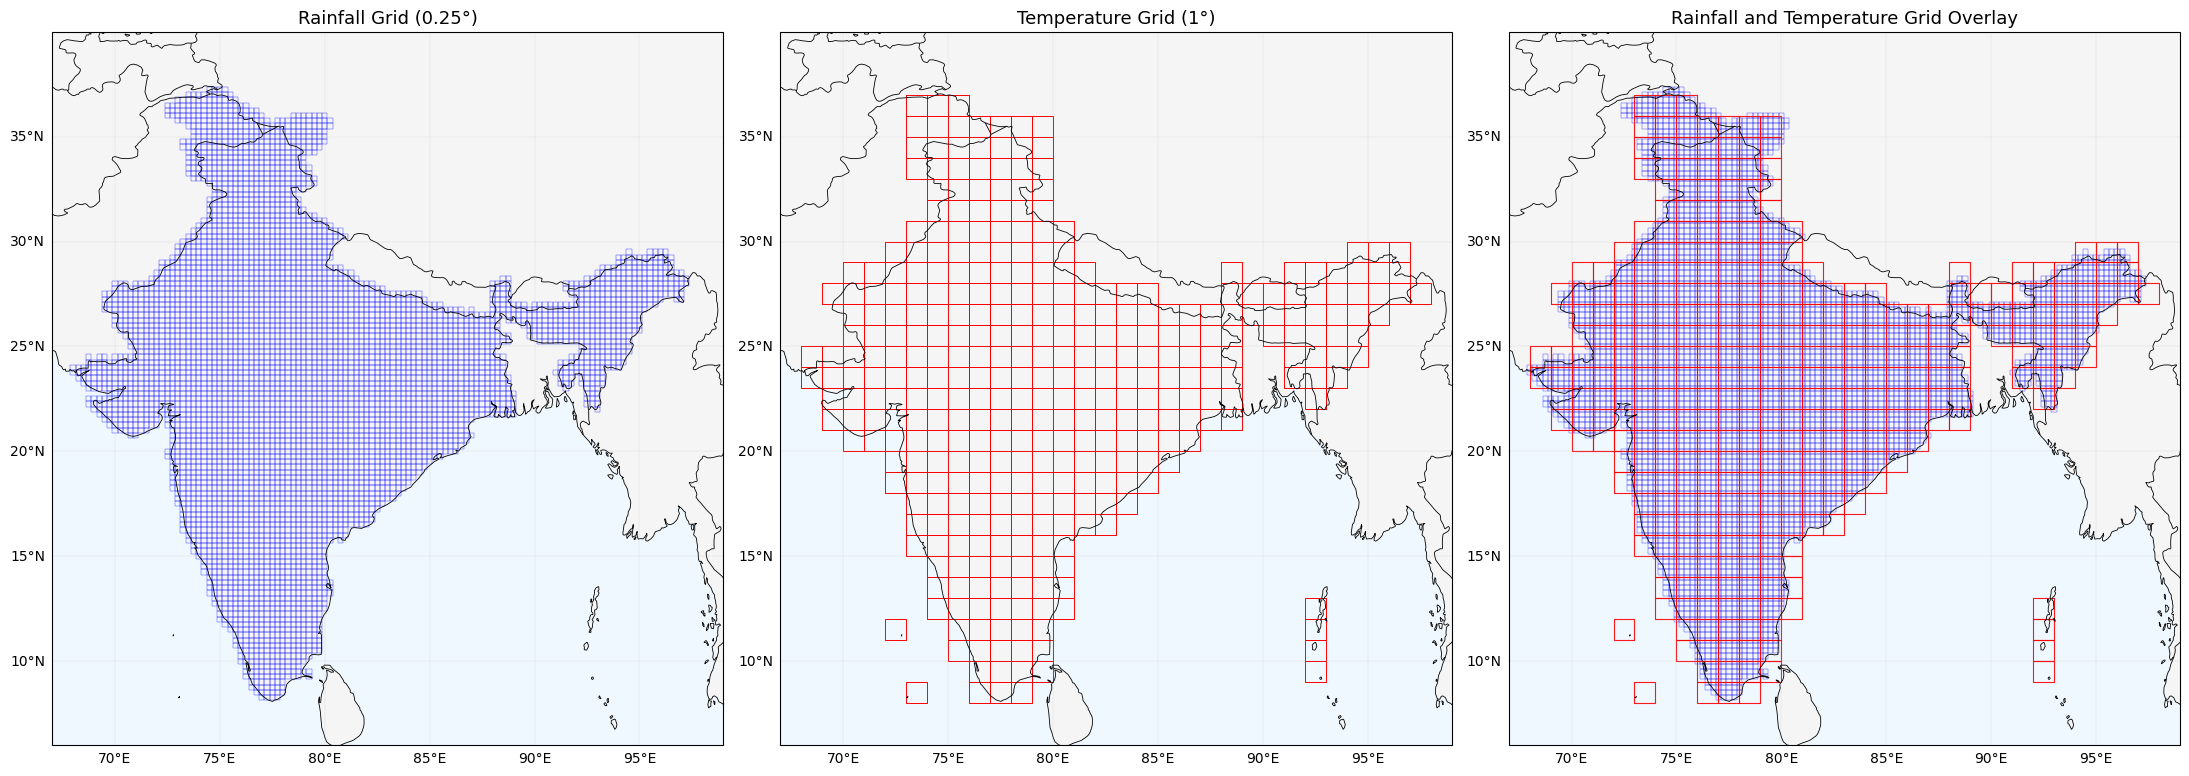

In [14]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle

# Grid resolutions
RAIN_RES = 0.25
TEMP_RES = 1.0

# Unique coordinate pairs
rain_cells = rainfall_df[
    ["latitude", "longitude"]
].drop_duplicates()

temp_cells = temperature_df[
    ["lat", "lon"]
].drop_duplicates()


def draw_grid(ax, cells, lat_col, lon_col, resolution,
              edgecolor, linewidth, alpha=1.0):

    half = resolution / 2

    rectangles = [
        Rectangle(
            (lon - half, lat - half),
            resolution,
            resolution
        )
        for lat, lon in zip(cells[lat_col], cells[lon_col])
    ]

    collection = PatchCollection(
        rectangles,
        facecolor="none",
        edgecolor=edgecolor,
        linewidth=linewidth,
        alpha=alpha,
        transform=ccrs.PlateCarree()
    )

    ax.add_collection(collection)


def setup_map(ax):
    ax.add_feature(cfeature.LAND, facecolor="whitesmoke")
    ax.add_feature(cfeature.OCEAN, facecolor="aliceblue")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.6)

    ax.set_extent([67, 99, 6, 39])

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.3,
        alpha=0.4
    )
    gl.top_labels = False
    gl.right_labels = False


# Create three maps
fig, axes = plt.subplots(
    1, 3,
    figsize=(22, 11),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

# 1. Rainfall grid
setup_map(axes[0])

draw_grid(
    axes[0], rain_cells,
    "latitude", "longitude",
    RAIN_RES, "blue", 0.25
)

axes[0].set_title("Rainfall Grid (0.25°)", fontsize=13)


# 2. Temperature grid
setup_map(axes[1])

draw_grid(
    axes[1], temp_cells,
    "lat", "lon",
    TEMP_RES, "red", 0.7
)

axes[1].set_title("Temperature Grid (1°)", fontsize=13)


# 3. Overlay
setup_map(axes[2])

draw_grid(
    axes[2], rain_cells,
    "latitude", "longitude",
    RAIN_RES, "blue", 0.3, 0.8
)

draw_grid(
    axes[2], temp_cells,
    "lat", "lon",
    TEMP_RES, "red", 0.8, 0.9
)

axes[2].set_title("Rainfall and Temperature Grid Overlay", fontsize=13)

plt.tight_layout()
plt.show()

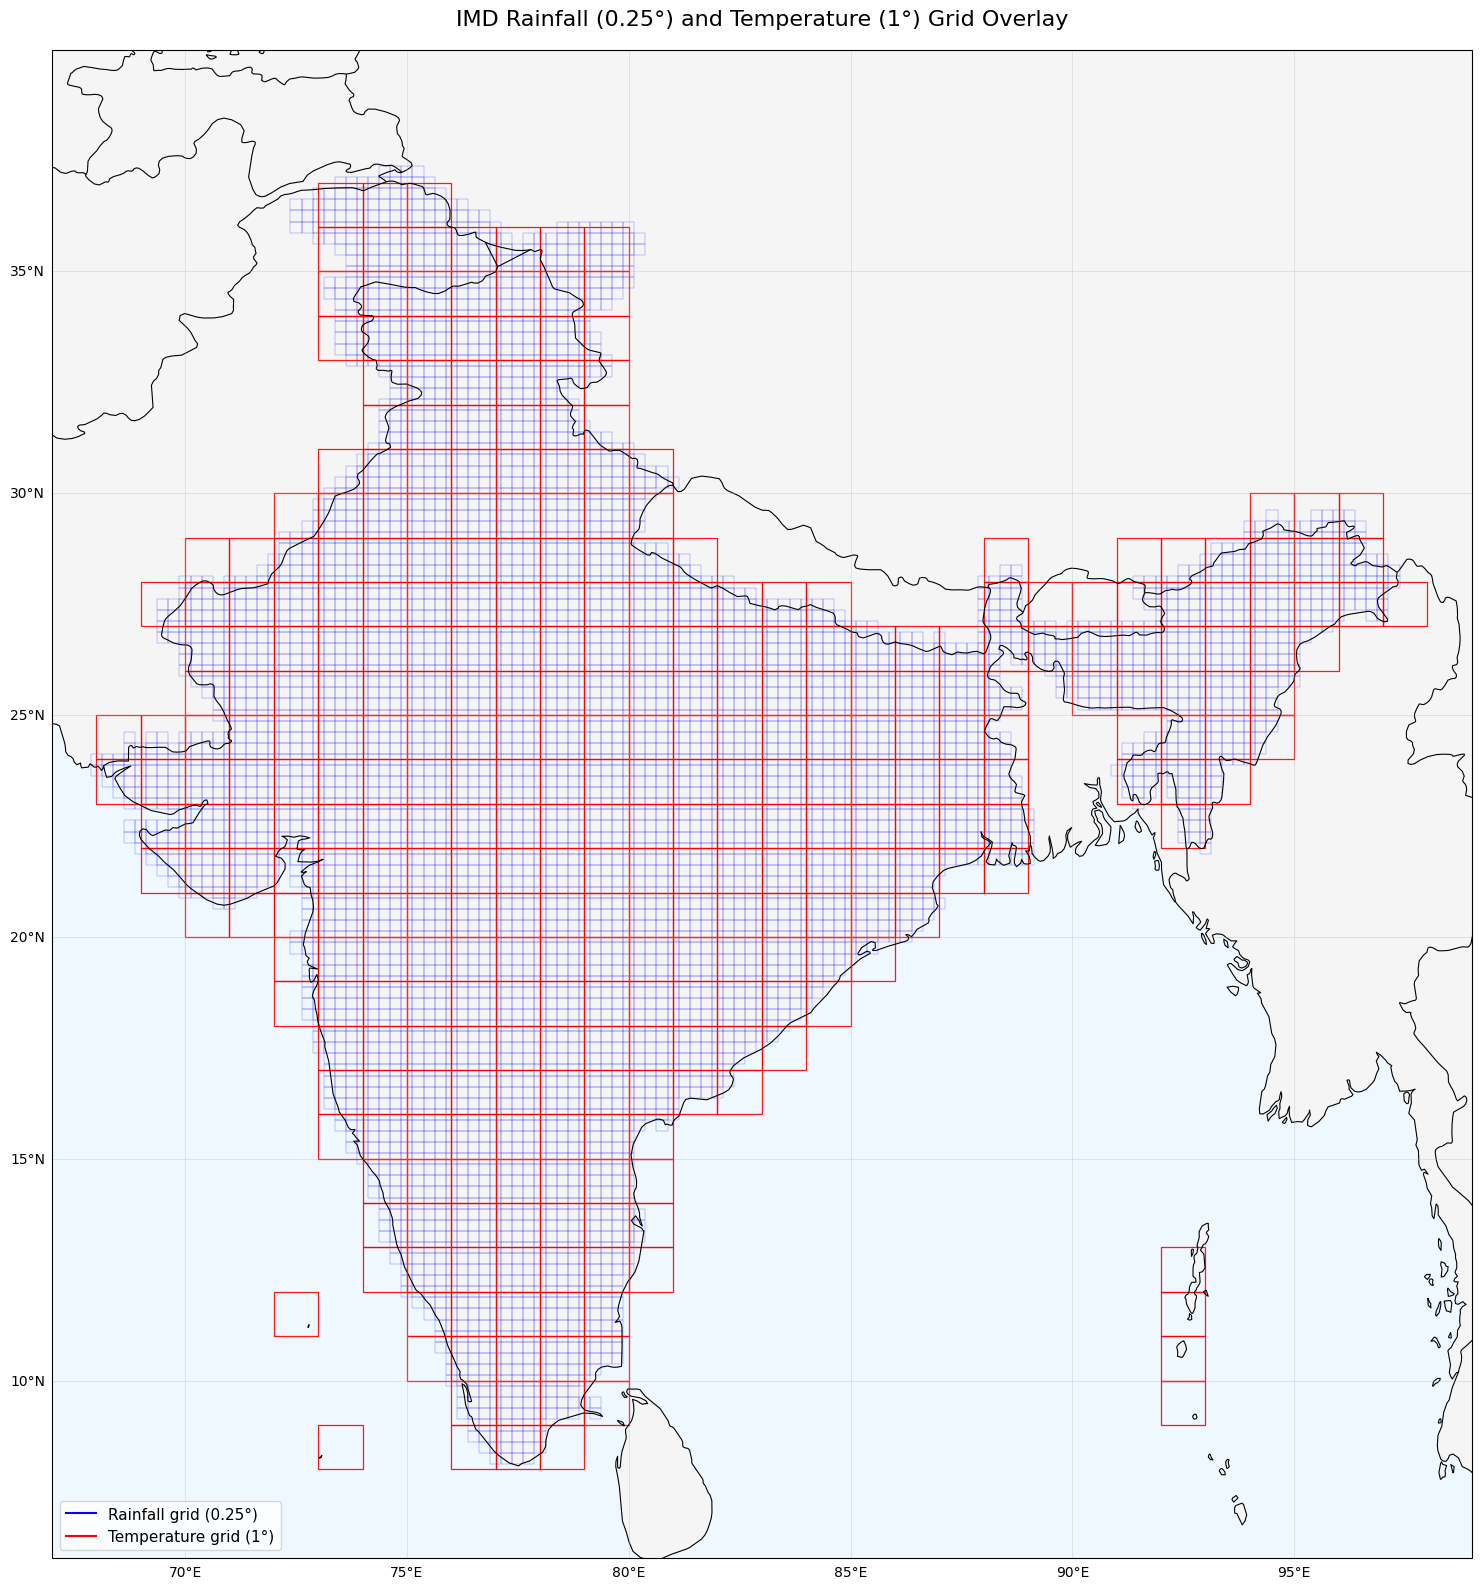

In [15]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(
    figsize=(16, 16),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

# Map background
ax.add_feature(cfeature.LAND, facecolor="whitesmoke")
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue")
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)

# Rainfall grid: 0.25° cells
rain_rectangles = [
    Rectangle(
        (lon - 0.125, lat - 0.125),
        0.25, 0.25
    )
    for lat, lon in zip(
        rain_cells["latitude"],
        rain_cells["longitude"]
    )
]

rain_collection = PatchCollection(
    rain_rectangles,
    facecolor="none",
    edgecolor="blue",
    linewidth=0.25,
    alpha=0.65,
    transform=ccrs.PlateCarree()
)

ax.add_collection(rain_collection)

# Temperature grid: 1° cells
temp_rectangles = [
    Rectangle(
        (lon - 0.5, lat - 0.5),
        1.0, 1.0
    )
    for lat, lon in zip(
        temp_cells["lat"],
        temp_cells["lon"]
    )
]

temp_collection = PatchCollection(
    temp_rectangles,
    facecolor="none",
    edgecolor="red",
    linewidth=0.9,
    alpha=0.9,
    transform=ccrs.PlateCarree()
)

ax.add_collection(temp_collection)

# Map extent and gridlines
ax.set_extent([67, 99, 6, 39])

gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.4,
    alpha=0.5
)
gl.top_labels = False
gl.right_labels = False

ax.set_title(
    "IMD Rainfall (0.25°) and Temperature (1°) Grid Overlay",
    fontsize=16,
    pad=18
)

ax.legend(
    handles=[
        plt.Line2D([], [], color="blue", label="Rainfall grid (0.25°)"),
        plt.Line2D([], [], color="red", label="Temperature grid (1°)")
    ],
    loc="lower left",
    fontsize=11
)

plt.tight_layout()
plt.show()


In [18]:
# Get unique coordinate pairs from both datasets
rain_cells = rainfall_df[
    ["latitude", "longitude"]
].drop_duplicates()

temp_cells = temperature_df[
    ["lat", "lon"]
].drop_duplicates()


results = []

for _, temp in temp_cells.iterrows():

    target_lat = temp["lat"]
    target_lon = temp["lon"]

    # Find rainfall coordinates within the temperature grid boundaries
    points = rain_cells[
        (rain_cells["latitude"] >= target_lat - 0.5 - 1e-9) &
        (rain_cells["latitude"] <= target_lat + 0.5 + 1e-9) &
        (rain_cells["longitude"] >= target_lon - 0.5 - 1e-9) &
        (rain_cells["longitude"] <= target_lon + 0.5 + 1e-9)
    ].copy()

    # Calculate weights based on position
    lat_diff = np.abs(points["latitude"] - target_lat)
    lon_diff = np.abs(points["longitude"] - target_lon)

    lat_weights = np.where(
        np.isclose(lat_diff, 0.5), 0.5, 1.0
    )

    lon_weights = np.where(
        np.isclose(lon_diff, 0.5), 0.5, 1.0
    )

    points["weight"] = lat_weights * lon_weights

    total_weight = points["weight"].sum()

    if total_weight > 0:
        aggregated_lat = (
            points["latitude"] * points["weight"]
        ).sum() / total_weight

        aggregated_lon = (
            points["longitude"] * points["weight"]
        ).sum() / total_weight
    else:
        aggregated_lat = np.nan
        aggregated_lon = np.nan

    results.append({
        "temp_lat": target_lat,
        "temp_lon": target_lon,
        "rain_coordinates": len(points),
        "total_weight": total_weight,
        "aggregated_rain_lat": aggregated_lat,
        "aggregated_rain_lon": aggregated_lon,
        "latitude_difference": aggregated_lat - target_lat,
        "longitude_difference": aggregated_lon - target_lon
    })


# Create final comparison table
coordinate_comparison = pd.DataFrame(results)

coordinate_comparison = coordinate_comparison.sort_values(
    ["temp_lat", "temp_lon"]
).reset_index(drop=True)

# Display the first 20 temperature locations and their comparisons
display(
    coordinate_comparison.head(20).round(6)
)

,temp_lat,temp_lon,rain_coordinates,total_weight,aggregated_rain_lat,aggregated_rain_lon,latitude_difference,longitude_difference
0,8.5,73.5,0,0.00,NaN,NaN,NaN,NaN
1,8.5,76.5,9,5.75,8.695652,76.760870,0.195652,0.260870
2,8.5,77.5,19,13.50,8.583333,77.481481,0.083333,-0.018519
3,8.5,78.5,3,1.25,8.700000,78.000000,0.200000,-0.500000
4,9.5,76.5,20,13.75,9.527273,76.572727,0.027273,0.072727
5,9.5,77.5,25,16.00,9.500000,77.500000,0.000000,0.000000
6,9.5,78.5,19,13.25,9.566038,78.452830,0.066038,-0.047170
7,9.5,79.5,4,2.75,9.454545,79.181818,-0.045455,-0.318182
8,9.5,92.5,0,0.00,NaN,NaN,NaN,NaN
9,10.5,75.5,7,3.50,10.642857,75.892857,0.142857,0.392857


In [21]:
import numpy as np
import pandas as pd

# Ensure date is in datetime format
rainfall_df["date"] = pd.to_datetime(rainfall_df["date"])

# Get the temperature grid coordinates
temp_cells = (
    temperature_df[["lat", "lon"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

daily_results = []

# Aggregate rainfall onto each 1° temperature grid cell
for _, temp_cell in temp_cells.iterrows():

    t_lat = temp_cell["lat"]
    t_lon = temp_cell["lon"]

    # Select rainfall grid points within the temperature cell
    selected_rain = rainfall_df[
        (rainfall_df["latitude"].between(t_lat - 0.5, t_lat + 0.5)) &
        (rainfall_df["longitude"].between(t_lon - 0.5, t_lon + 0.5))
    ].copy()

    # Identify interior, edge and corner points
    lat_diff = np.abs(selected_rain["latitude"] - t_lat)
    lon_diff = np.abs(selected_rain["longitude"] - t_lon)

    is_boundary_lat = np.isclose(lat_diff, 0.5)
    is_boundary_lon = np.isclose(lon_diff, 0.5)

    # Assign weights
    selected_rain["weight"] = np.where(
        is_boundary_lat & is_boundary_lon, 0.25,
        np.where(is_boundary_lat | is_boundary_lon, 0.5, 1.0)
    )

    # Remove missing rainfall observations
    selected_rain = selected_rain.dropna(subset=["rainfall_mm"])

    # Calculate weighted rainfall
    selected_rain["weighted_rain"] = (
        selected_rain["rainfall_mm"] * selected_rain["weight"]
    )

    # Aggregate for each date
    daily = selected_rain.groupby("date").agg(
        weighted_sum=("weighted_rain", "sum"),
        valid_weight=("weight", "sum")
    ).reset_index()

    # Calculate weighted average
    daily["daily_rain"] = (
        daily["weighted_sum"] / daily["valid_weight"]
    )

    # Require minimum valid weight of 4
    daily.loc[daily["valid_weight"] == 0, "daily_rain"] = np.nan

    daily["lat"] = t_lat
    daily["lon"] = t_lon

    daily_results.append(
        daily[["date", "lat", "lon", "daily_rain"]]
    )


# Combine daily results for all temperature-grid cells
daily_rainfall = pd.concat(daily_results, ignore_index=True)

# MONTHLY AGGREGATION

daily_rainfall["year"] = daily_rainfall["date"].dt.year
daily_rainfall["month"] = daily_rainfall["date"].dt.month

monthly_rainfall = daily_rainfall.groupby(
    ["year", "month", "lat", "lon"]
).agg(
    monthly_accumulated_rain=("daily_rain", "sum"),
    monthly_mean_rain=("daily_rain", "mean"),
    valid_days=("daily_rain", "count")
).reset_index()

# Number of calendar days in each month
monthly_rainfall["days_in_month"] = pd.to_datetime(
    monthly_rainfall[["year", "month"]].assign(day=1)
).dt.days_in_month

# Do not report a monthly accumulation for incomplete months
monthly_rainfall.loc[
    monthly_rainfall["valid_days"] != monthly_rainfall["days_in_month"],
    "monthly_accumulated_rain"
] = np.nan

# Require at least 20 valid days for the monthly mean
monthly_rainfall.loc[
    monthly_rainfall["valid_days"] < 20,
    "monthly_mean_rain"
] = np.nan

# Arrange columns
monthly_rainfall = monthly_rainfall[
    [
        "year",
        "month",
        "lat",
        "lon",
        "monthly_accumulated_rain",
        "monthly_mean_rain",
        "valid_days"
    ]
]


# save csv

OUTPUT_DIR = PRECIPITATION_DIR / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_path = OUTPUT_DIR / "trial_1951.csv"

monthly_rainfall.to_csv(output_path, index=False)

print("Monthly aggregation completed.")
print(f"Saved to: {output_path}")
print(f"Total records: {len(monthly_rainfall)}")

# INSPECT OUTPUT

print("\n--- FIRST 5 RECORDS ---")
display(monthly_rainfall.head())

print("\n--- MIDDLE 5 RECORDS ---")
middle = len(monthly_rainfall) // 2
display(monthly_rainfall.iloc[middle-2:middle+3])

print("\n--- LAST 5 RECORDS ---")
display(monthly_rainfall.tail())

Monthly aggregation completed.
Saved to: /home/sharanya/Climate-Change-Awareness-Dashboard/precipitation/data/processed/trial_1951.csv
Total records: 4224

--- FIRST 5 RECORDS ---


,year,month,lat,lon,monthly_accumulated_rain,monthly_mean_rain,valid_days
0,1951,1,8.5,76.5,11.604210,0.374329,31
1,1951,1,8.5,77.5,45.013756,1.452057,31
2,1951,1,8.5,78.5,21.057429,0.679272,31
3,1951,1,9.5,76.5,16.559665,0.534183,31
4,1951,1,9.5,77.5,17.103688,0.551732,31



--- MIDDLE 5 RECORDS ---


,year,month,lat,lon,monthly_accumulated_rain,monthly_mean_rain,valid_days
2110,1951,6,36.5,74.5,83.145613,2.771520,30
2111,1951,6,36.5,75.5,88.392767,2.946426,30
2112,1951,7,8.5,76.5,183.183207,5.909136,31
2113,1951,7,8.5,77.5,39.608647,1.277698,31
2114,1951,7,8.5,78.5,6.800332,0.219366,31



--- LAST 5 RECORDS ---


,year,month,lat,lon,monthly_accumulated_rain,monthly_mean_rain,valid_days
4219,1951,12,35.5,78.5,0.013454,0.000434,31
4220,1951,12,35.5,79.5,0.070179,0.002264,31
4221,1951,12,36.5,73.5,15.878827,0.512220,31
4222,1951,12,36.5,74.5,67.325211,2.171781,31
4223,1951,12,36.5,75.5,86.169815,2.779671,31
